# Medicare claims analysis: spending, readmissions and care-management targeting

Runs on the tables built by the dbt project (`dbt build --project-dir dbt --profiles-dir dbt`), stored in `medicare.duckdb`.

Three questions a health plan or ACO analytics team would ask:
1. **Where does the money go?** PMPM by setting, how concentrated spending is, and how it scales with chronic conditions.
2. **How often are patients readmitted within 30 days, and for which conditions?**
3. **Can we pick next year's high-cost members this year**, so a care-management team with a fixed caseload calls the right people?

**About the data.** CMS's DE-SynPUF is synthetic. CMS built it for developing and testing programs that will later run on real
Medicare data, and warns that inferences drawn from it about Medicare "will be misleading and often incorrect"
(DE-SynPUF Data Users Document). So the numbers below show what the pipeline produces, and where the synthetic data behaves unlike
real claims that is called out. Claim counts also fall in 2010 (CMS attributes this to attrition from death and the disclosure
treatment), so 2008–2009 are the main comparison years.

In [1]:
from pathlib import Path

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DB = Path("../medicare.duckdb") if Path("../medicare.duckdb").exists() else Path("medicare.duckdb")
IMG = DB.parent / "images"
IMG.mkdir(exist_ok=True)
con = duckdb.connect(str(DB), read_only=True)
q = lambda sql: con.sql(sql).df()
pd.set_option("display.width", 160)

# Reference categorical palette (light mode) and text colors
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "legend.frameon": False,
})

## 1. Where does the money go?

In [2]:
util = q("select * from agg_utilization_by_year order by coverage_year")
util[["coverage_year", "members", "member_months", "pmpm_total", "pmpm_ip", "pmpm_op", "pmpm_carrier",
      "admits_per_1000", "avg_length_of_stay", "outpatient_claims_per_1000"]].round(1)

,coverage_year,members,member_months,pmpm_total,pmpm_ip,pmpm_op,pmpm_carrier,admits_per_1000,avg_length_of_stay,outpatient_claims_per_1000
0,2008,111676,1303587.0,354.0,196.0,55.1,102.9,238.3,5.9,2582.7
1,2009,108555,1300350.0,378.0,192.6,67.7,117.7,227.3,5.8,2972.8
2,2010,107099,1280772.0,222.0,109.3,38.1,74.6,125.3,5.5,1629.8


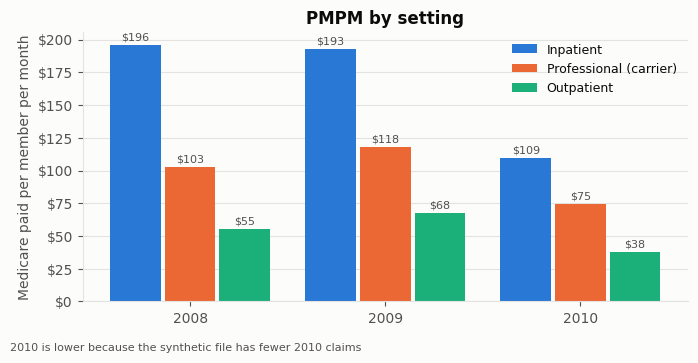

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.6))
years = util.coverage_year.astype(str).values
x = np.arange(len(years))
w = 0.26
for i, (col, label, color) in enumerate([("pmpm_ip", "Inpatient", BLUE), ("pmpm_carrier", "Professional (carrier)", ORANGE),
                                         ("pmpm_op", "Outpatient", AQUA)]):
    bars = ax.bar(x + (i - 1) * (w + 0.02), util[col], w, color=color, label=label)
    ax.bar_label(bars, fmt="$%.0f", fontsize=8, color=INK2, padding=2)
ax.set_xticks(x, years)
ax.set_ylabel("Medicare paid per member per month")
ax.yaxis.set_major_formatter(lambda v, _: f"${v:,.0f}")
ax.grid(axis="x", visible=False)
ax.set_title("PMPM by setting")
ax.legend(loc="upper right", fontsize=9)
fig.text(0.01, 0.01, "2010 is lower because the synthetic file has fewer 2010 claims", color=INK2, fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(IMG / "pmpm_by_setting.png", dpi=150)
plt.show()

### Spending is highly concentrated

In [4]:
conc = q("select * from agg_cost_concentration order by coverage_year, spend_band")
conc.pivot(index="spend_band", columns="coverage_year", values="share_of_spend").round(3)

coverage_year,2008,2009,2010
spend_band,,,
1. Top 1%,0.177,0.137,0.166
2. Next 4% (top 1–5%),0.304,0.248,0.263
3. Next 15% (top 5–20%),0.332,0.346,0.318
4. Next 30% (top 20–50%),0.158,0.212,0.200
5. Bottom 50%,0.029,0.056,0.053


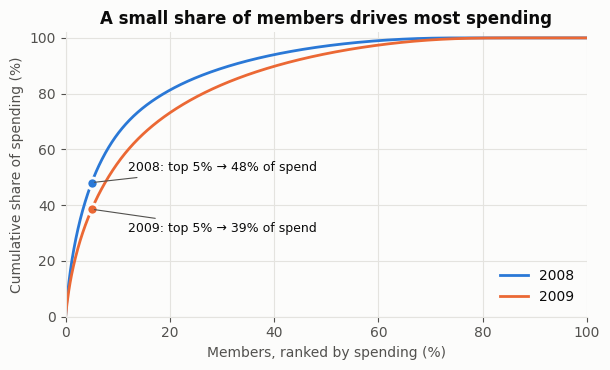

In [5]:
lorenz = q("""
    select coverage_year,
           row_number() over (partition by coverage_year order by medicare_paid_total desc) * 1.0
               / count(*) over (partition by coverage_year)                                  as share_of_members,
           sum(medicare_paid_total) over (partition by coverage_year order by medicare_paid_total desc
                                          rows between unbounded preceding and current row)
               / sum(medicare_paid_total) over (partition by coverage_year)                  as cum_share_of_spend
    from fct_member_years
    where coverage_year in (2008, 2009) and member_months > 0
""")
fig, ax = plt.subplots(figsize=(6.2, 3.8))
for yr, color in [(2008, BLUE), (2009, ORANGE)]:
    d = lorenz[lorenz.coverage_year == yr].sort_values("share_of_members")
    d = d.iloc[:: max(1, len(d) // 2000)]
    ax.plot(d.share_of_members * 100, d.cum_share_of_spend * 100, color=color, lw=2, label=str(yr))
for yr, color, dy in [(2008, BLUE, 4), (2009, ORANGE, -8)]:
    top5 = conc[(conc.coverage_year == yr) & conc.spend_band.str[:1].isin(["1", "2"])].share_of_spend.sum()
    ax.annotate(f"{yr}: top 5% → {top5:.0%} of spend", (5, top5 * 100), xytext=(12, top5 * 100 + dy),
                color=INK, fontsize=9, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
    ax.plot([5], [top5 * 100], "o", ms=8, color=color, mec=SURFACE, mew=2)
ax.set_xlim(0, 100); ax.set_ylim(0, 102)
ax.set_xlabel("Members, ranked by spending (%)")
ax.set_ylabel("Cumulative share of spending (%)")
ax.set_title("A small share of members drives most spending")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(IMG / "cost_concentration.png", dpi=150)
plt.show()

### Spending rises steeply with the number of chronic conditions

In [6]:
burden = q("select * from agg_chronic_burden where coverage_year = 2009 order by chronic_conditions")
burden[["chronic_conditions_label", "members", "share_of_members", "pmpm_total", "admits_per_1000", "share_of_spend"]].round(3)

,chronic_conditions_label,members,share_of_members,pmpm_total,admits_per_1000,share_of_spend
0,0,31172,0.287,26.718,6.031,0.020
1,1,13021,0.120,143.176,55.558,0.045
2,2,12857,0.118,245.731,119.693,0.077
3,3,12367,0.114,351.701,190.556,0.106
4,4,11510,0.106,484.470,278.684,0.136
5,5,9705,0.089,645.577,392.508,0.153
6,6+,17923,0.165,1056.292,714.912,0.462


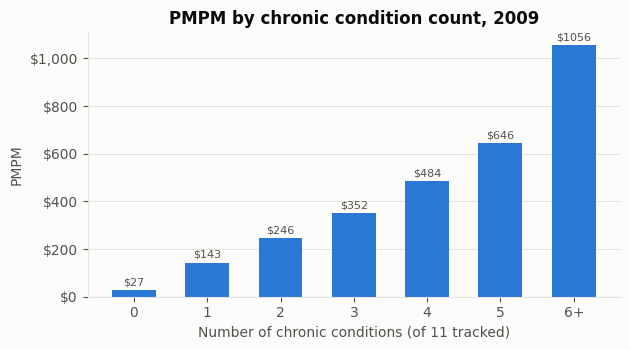

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
bars = ax.bar(burden.chronic_conditions_label, burden.pmpm_total, color=BLUE, width=0.6)
ax.bar_label(bars, fmt="$%.0f", fontsize=8, color=INK2, padding=2)
ax.set_xlabel("Number of chronic conditions (of 11 tracked)")
ax.set_ylabel("PMPM")
ax.yaxis.set_major_formatter(lambda v, _: f"${v:,.0f}")
ax.grid(axis="x", visible=False)
ax.set_title("PMPM by chronic condition count, 2009")
fig.tight_layout()
fig.savefig(IMG / "chronic_burden.png", dpi=150)
plt.show()

In [8]:
cond = q("select * from agg_conditions where coverage_year = 2009 order by share_of_spend_with desc")
cond.assign(pmpm_ratio=cond.pmpm_with / cond.pmpm_without).round(3)

,coverage_year,condition,prevalence,pmpm_with,pmpm_without,share_of_spend_with,pmpm_ratio
0,2009,Ischemic heart disease,0.502,620.154,132.897,0.825,4.666
1,2009,Diabetes,0.439,658.976,157.475,0.767,4.185
2,2009,Heart failure,0.363,703.649,192.097,0.677,3.663
3,2009,Chronic kidney disease,0.218,952.148,217.391,0.551,4.380
4,2009,Depression,0.259,673.179,274.944,0.461,2.448
5,2009,Alzheimer's / dementia,0.243,700.584,274.305,0.451,2.554
6,2009,COPD,0.165,913.037,272.143,0.399,3.355
7,2009,Rheumatoid arthritis / osteoarthritis,0.184,704.676,304.218,0.344,2.316
8,2009,Osteoporosis,0.202,627.474,314.933,0.335,1.992
9,2009,Cancer,0.086,818.988,336.513,0.186,2.434


## 2. 30-day readmissions

Definitions (stay merging in `dbt/models/intermediate/int_inpatient_stays.sql`, readmission flags in
`dbt/models/marts/fct_inpatient_stays.sql`, both covered by dbt unit tests):
overlapping claims, same-day admissions and next-day transfers to a different provider are merged into one stay; an **index stay** is discharged alive with at least 30 days of
follow-up left in the data; a **readmission** is any stay starting 1–30 days after discharge (all-cause).
Condition groups follow simplified CMS Hospital Readmissions Reduction Program (HRRP) ICD-9 cohorts.

In [9]:
readm = q("select * from agg_readmissions order by discharge_year, condition_group")
readm.pivot(index="condition_group", columns="discharge_year", values="readmission_rate_30d").round(3)

discharge_year,2008,2009,2010
condition_group,,,
AMI,0.140,0.077,0.036
All conditions,0.147,0.074,0.042
COPD,0.152,0.075,0.046
Heart failure,0.150,0.090,0.032
Other,0.147,0.072,0.042
Pneumonia,0.145,0.074,0.051


In [10]:
readm.pivot(index="condition_group", columns="discharge_year", values="index_stays")

discharge_year,2008,2009,2010
condition_group,,,
AMI,657,572,329
All conditions,25929,24717,13405
COPD,966,888,459
Heart failure,1316,1283,657
Other,21772,20872,11448
Pneumonia,1218,1102,512


The 2008 all-cause rate (about 15%) is the same order as published real-Medicare figures from a few years earlier (Jencks et al.,
NEJM 2009: 19.6% for 2003–04 discharges). The drop to about 7% in 2009 and 4% in 2010 is an artifact of the synthetic file: repeat
hospital stays per admitted patient fall from 1.65 (2008) to 1.31 (2009) and 1.14 (2010), and 2010 also has fewer claims overall.
**Compare conditions within a year, not trends across years.** Unlike real Medicare data, the condition
groups barely differ from each other, which fits CMS's warning that the synthetic process weakens relationships between variables.
What *does* separate patients is their overall chronic burden (next table): readmission rates rise steadily with the number of chronic conditions.
This is an association: the condition flags come from the same calendar year as the stay, so the stay itself can contribute to them, and the
0-condition group is small (129 index stays in 2008).

In [11]:
by_burden = q("""
    select s.discharge_year,
           case when m.chronic_condition_count >= 6 then '6+' else m.chronic_condition_count::varchar end as chronic_conditions,
           count(*) as index_stays,
           avg(s.is_readmitted_30d::int) as readmission_rate_30d
    from fct_inpatient_stays s
    join fct_member_years m on m.bene_id = s.bene_id and m.coverage_year = s.discharge_year
    where s.is_index_stay and s.discharge_year in (2008, 2009)
    group by all
    order by all
""")
by_burden.pivot(index="chronic_conditions", columns="discharge_year", values="readmission_rate_30d").round(3)

discharge_year,2008,2009
chronic_conditions,,
0,0.023,0.006
1,0.027,0.006
2,0.058,0.022
3,0.071,0.032
4,0.078,0.045
5,0.119,0.057
6+,0.180,0.104


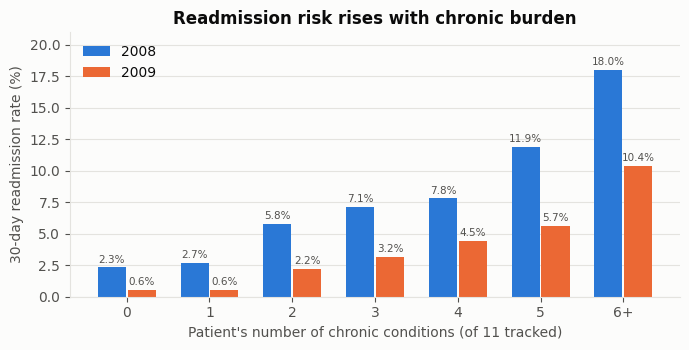

In [12]:
labels = ["0", "1", "2", "3", "4", "5", "6+"]
fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(labels))
for i, (yr, color) in enumerate([(2008, BLUE), (2009, ORANGE)]):
    d = by_burden[by_burden.discharge_year == yr].set_index("chronic_conditions").loc[labels]
    bars = ax.bar(x + (i - 0.5) * 0.36, d.readmission_rate_30d * 100, 0.34, color=color, label=str(yr))
    ax.bar_label(bars, fmt="%.1f%%", fontsize=7.5, color=INK2, padding=2)
ax.set_xticks(x, labels)
ax.set_xlabel("Patient's number of chronic conditions (of 11 tracked)")
ax.set_ylabel("30-day readmission rate (%)")
ax.set_ylim(0, 21)
ax.grid(axis="x", visible=False)
ax.set_title("Readmission risk rises with chronic burden")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(IMG / "readmissions_by_burden.png", dpi=150)
plt.show()

## 3. Care-management targeting: who will be high-cost next year?

A care-management team can enroll a fixed number of members. The question is which members to call **this** year so the list
contains as many of **next** year's high-cost members as possible.

- **Target:** member is in the top 5% of Medicare spending next year (among members enrolled in both years).
- **Features (all known by the end of this year):** spending by setting, admissions, inpatient days, outpatient claims,
  the 11 chronic-condition flags and their count, age, sex, ESRD, coverage months.
- **Validation over time:** train on 2008 → 2009, test once on 2009 → 2010. Model choice uses 5-fold cross-validation inside the training year only.
- **Baselines** a team would use without a model: rank by this year's spending; rank by chronic-condition count.
- **Metric that matches the decision:** of next year's high-cost members, what share is on a list of the top k% (k = 1, 5, 10),
  and what share of next year's spending those listed members account for.

In [13]:
my = q("select * from fct_member_years where member_months > 0")
CONDITIONS = [c for c in my.columns if c.startswith("has_") and c != "has_esrd"]


def build_pairs(year):
    now = my[my.coverage_year == year]
    nxt = my[my.coverage_year == year + 1][["bene_id", "medicare_paid_total"]].rename(columns={"medicare_paid_total": "next_year_paid"})
    d = now.merge(nxt, on="bene_id")
    d["high_cost_next_year"] = (d.next_year_paid > d.next_year_paid.quantile(0.95)).astype(int)
    return d.reset_index(drop=True)


def features(d):
    X = pd.DataFrame({
        "log_paid_total": np.log1p(d.medicare_paid_total.clip(lower=0)),
        "log_paid_inpatient": np.log1p(d.medicare_paid_ip.clip(lower=0)),
        "log_paid_outpatient": np.log1p(d.medicare_paid_op.clip(lower=0)),
        "log_paid_professional": np.log1p(d.medicare_paid_carrier.clip(lower=0)),
        "inpatient_admissions": d.inpatient_admissions,
        "inpatient_days": d.inpatient_days,
        "outpatient_claims": d.outpatient_claims,
        "chronic_condition_count": d.chronic_condition_count,
        "age": d.age,
        "female": (d.sex == "Female").astype(int),
        "esrd": d.has_esrd.astype(int),
        "member_months": d.member_months,
        "hmo_months": d.hmo_months,
        "part_d_months": d.part_d_months,
    })
    for c in CONDITIONS:
        X[c] = d[c].astype(int)
    return X


train, test = build_pairs(2008), build_pairs(2009)
X_train, y_train = features(train), train.high_cost_next_year.values
X_test, y_test = features(test), test.high_cost_next_year.values
print(f"train 2008→2009: {len(train):,} members, {y_train.mean():.1%} high-cost next year")
print(f"test  2009→2010: {len(test):,} members, {y_test.mean():.1%} high-cost next year")

train 2008→2009: 104,674 members, 5.0% high-cost next year
test  2009→2010: 106,186 members, 5.0% high-cost next year


How persistent is high cost from one year to the next in this data?

In [14]:
persist = q("""
    with ranked as (
        select bene_id, coverage_year,
               percent_rank() over (partition by coverage_year order by medicare_paid_total desc) < 0.05 as top5
        from fct_member_years
        where member_months > 0
    )
    select a.coverage_year as from_year, a.coverage_year + 1 as to_year,
           avg(b.top5::int) as share_still_top5
    from ranked a join ranked b on a.bene_id = b.bene_id and b.coverage_year = a.coverage_year + 1
    where a.top5
    group by all order by 1
""")
persist.round(3)

,from_year,to_year,share_still_top5
0,2008,2009,0.245
1,2009,2010,0.141


### Model selection with cross-validation on the training year only

In [15]:
candidates = {
    "logistic regression": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.3)),
    "LightGBM": lambda: lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=100,
                                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=0, verbose=-1),
}
cv = StratifiedKFold(5, shuffle=True, random_state=0)
cv_rows = []
for name, make in candidates.items():
    scores = []
    for tr_idx, va_idx in cv.split(X_train, y_train):
        m = make().fit(X_train.iloc[tr_idx], y_train[tr_idx])
        scores.append(average_precision_score(y_train[va_idx], m.predict_proba(X_train.iloc[va_idx])[:, 1]))
    cv_rows.append({"model": name, "cv_pr_auc_mean": np.mean(scores), "cv_pr_auc_sd": np.std(scores)})
cv_table = pd.DataFrame(cv_rows).round(3)
cv_table

,model,cv_pr_auc_mean,cv_pr_auc_sd
0,logistic regression,0.273,0.014
1,LightGBM,0.294,0.010


In [16]:
best_name = cv_table.sort_values("cv_pr_auc_mean", ascending=False).model.iloc[0]
final = candidates[best_name]().fit(X_train, y_train)
print("selected:", best_name)

selected: LightGBM


### One evaluation on the 2009 → 2010 test year

In [17]:
rng = np.random.default_rng(0)
tiebreak = rng.random(len(test)) * 1e-6
scores = {
    "Random list": rng.random(len(test)),
    "Rank by this year's spending": test.medicare_paid_total.values + tiebreak,
    "Rank by chronic-condition count": test.chronic_condition_count.values + test.medicare_paid_total.values / 1e8 + tiebreak,
    f"Model ({best_name})": final.predict_proba(X_test)[:, 1],
}


def list_metrics(score, k):
    n = int(round(len(test) * k))
    top = np.argsort(-score)[:n]
    return y_test[top].sum() / y_test.sum(), test.next_year_paid.values[top].sum() / test.next_year_paid.sum()


rows = []
for name, s in scores.items():
    row = {"approach": name, "PR-AUC": average_precision_score(y_test, s), "ROC-AUC": roc_auc_score(y_test, s)}
    for k in (0.01, 0.05, 0.10):
        rec, spend = list_metrics(s, k)
        row[f"high-cost caught, top {k:.0%} list"] = rec
        row[f"next-year spend on top {k:.0%} list"] = spend
    rows.append(row)
results = pd.DataFrame(rows).set_index("approach")
results.round(3).T

approach,Random list,Rank by this year's spending,Rank by chronic-condition count,Model (LightGBM)
PR-AUC,0.051,0.101,0.098,0.172
ROC-AUC,0.501,0.696,0.705,0.733
"high-cost caught, top 1% list",0.012,0.036,0.030,0.098
next-year spend on top 1% list,0.012,0.026,0.025,0.057
"high-cost caught, top 5% list",0.054,0.141,0.132,0.208
next-year spend on top 5% list,0.053,0.112,0.113,0.151
"high-cost caught, top 10% list",0.097,0.228,0.235,0.309
next-year spend on top 10% list,0.101,0.192,0.209,0.248


Bootstrap confidence interval for the gain over the spending-rank baseline at a 5% list (1,000 resamples of test members).

In [18]:
model_score = scores[f"Model ({best_name})"]
base_score = scores["Rank by this year's spending"]
n5 = int(round(len(test) * 0.05))
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(test), len(test))
    ys, ms, bs = y_test[idx], model_score[idx], base_score[idx]
    m_top, b_top = np.argsort(-ms)[:n5], np.argsort(-bs)[:n5]
    boot.append((ys[m_top].sum() - ys[b_top].sum()) / ys.sum())
lo, hi = np.percentile(boot, [2.5, 97.5])
gain = results.loc[f"Model ({best_name})", "high-cost caught, top 5% list"] - results.loc["Rank by this year's spending", "high-cost caught, top 5% list"]
print(f"gain in share of high-cost members caught at a 5% list: {gain * 100:+.1f} percentage points "
      f"(95% CI {lo * 100:+.1f} to {hi * 100:+.1f})")

gain in share of high-cost members caught at a 5% list: +6.7 percentage points (95% CI +5.7 to +7.6)


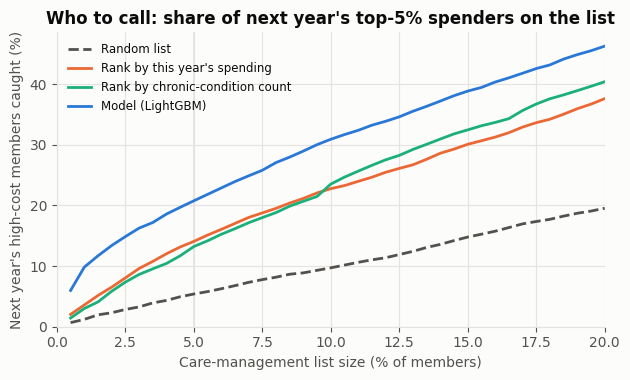

In [19]:
fig, ax = plt.subplots(figsize=(6.4, 3.9))
ks = np.linspace(0.005, 0.20, 40)
for (name, s), color in zip(scores.items(), [INK2, ORANGE, AQUA, BLUE]):
    order = np.argsort(-s)
    caught = [y_test[order[: int(round(len(test) * k))]].sum() / y_test.sum() * 100 for k in ks]
    ax.plot(ks * 100, caught, lw=2, color=color, label=name, ls="--" if name == "Random list" else "-")
ax.axvline(5, color=GRID, lw=1.2, zorder=0)
ax.set_xlabel("Care-management list size (% of members)")
ax.set_ylabel("Next year's high-cost members caught (%)")
ax.set_title("Who to call: share of next year's top-5% spenders on the list")
ax.legend(fontsize=8.5, loc="upper left")
ax.set_xlim(0, 20); ax.set_ylim(0, None)
fig.tight_layout()
fig.savefig(IMG / "high_cost_capture.png", dpi=150)
plt.show()

In [20]:
if best_name == "LightGBM":
    imp = pd.Series(final.booster_.feature_importance("gain"), index=X_train.columns)
else:
    imp = pd.Series(np.abs(final[-1].coef_[0]), index=X_train.columns)
(imp / imp.sum()).sort_values(ascending=False).head(10).round(3).rename("share of importance")

log_paid_professional      0.409
log_paid_outpatient        0.150
log_paid_total             0.148
chronic_condition_count    0.059
age                        0.040
outpatient_claims          0.033
inpatient_days             0.032
log_paid_inpatient         0.024
esrd                       0.018
part_d_months              0.011
Name: share of importance, dtype: float64

## What this shows, and what it would take on real data

- **The pipeline works end to end** on CMS-format claims: typed staging, stays with transfer handling, readmission flags,
  member-year facts and plan-level marts, with dbt tests (including unit tests of the stay-merging and readmission logic)
  and a reconciliation test between claims and the beneficiary summary file.
- **Spending concentration and the chronic-condition gradient are strong and stable** across years.
- **Year-to-year prediction is weak here**, and high cost barely persists in this file:
  only 24.5% of 2008's top-5% members are in the top 5% again in 2009, and 14% from 2009 to 2010. The weaker 2009 → 2010 link likely explains
  why the test PR-AUC (0.17) is below the cross-validated training-year figure (0.29). The model still beats the simple rankings a team would use
  (see the table and bootstrap interval above). Because the synthetic file's weak year-to-year link limits every method, the same evaluation
  should be rerun on real claims before choosing an approach.
- **Next steps on real data:** add HCC risk scores, prescription drug events, and social-risk variables; tune the list size to the team's
  actual caseload; and track outcomes of the members called (the goal is avoidable cost, not just predicting cost).